# 02-0 · Oxford-IIIT Pet: VGG16-Baseline

- **Ziel:** 37 Rassen klassifizieren; Katze/Hund zusätzlich aus den Rassenwahrscheinlichkeiten ableiten.
- **Ansatz:** ImageNet-vortrainiertes VGG16 einfrieren und einen eigenen kleinen Kopf trainieren.
- **Ergebnis:** wiederladbarer Kopf, feste Bildmerkmale, dokumentierte Testmetriken und gemeinsame Bildauswahl.
- **Reihenfolge:** dieses Notebook → probly oder shapiq → Kombination.

| Notebook | Fragestellung |
| :--- | :--- |
| **02-0 · Baseline** | Wie entsteht unser Bildklassifikator? |
| [02-1 · probly](dan_02-1_oxford-pets-probly.ipynb) | Wie brauchbar ist seine Unsicherheit? |
| [02-2 · shapiq](dan_02-2_oxford-pets-shapiq.ipynb) | Welche Bildinformationen bestimmen die Rasse? |
| [02-3 · Kombination](dan_02-3_oxford-pets-probly-shapiq.ipynb) | Welche Bildinformationen tragen zur Unsicherheit bei? |

## 1. Umgebung und Einstellungen

- Kernel: **SEP Gruppe D — shapiq-probly**.
- Benötigt: PyTorch, torchvision, scikit-learn, NumPy, Matplotlib, Pillow und IPython.
- Erster Lauf: ungefähr 0,8 GB Bildarchive und 0,5 GB VGG-Gewichte; einschließlich entpackter Daten und Caches mehrere GB Speicher.
- Passende Merkmalscaches und der gespeicherte Kopf werden wiederverwendet. `RETRAIN_BASELINE = True` erzwingt neues Kopftraining.
- Daten und Modellartefakte liegen außerhalb von Git. Die gemeinsame Hilfsdatei hält Laden und Training über die Reihe konsistent.

In [ ]:
from __future__ import annotations

import json
import random
import sys
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import Markdown, display
from PIL import Image as PILImage
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, top_k_accuracy_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import OxfordIIITPet
from torchvision.models import VGG16_Weights, vgg16

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src" / "probly").is_dir()
)
DATA_ROOT = REPO_ROOT / "data"
ARTIFACT_DIR = REPO_ROOT / "artifacts" / "oxford-pets-vgg16"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ARTIFACT_DIR / "torch_hub"))

SEED = 0
RETRAIN_BASELINE = False
FEATURE_DIM = 4096
EXTRACTION_BATCH_SIZE = 4
BATCH_SIZE = 64
MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

VERSIONS = {
    package: version(package)
    for package in ("torch", "torchvision", "scikit-learn", "numpy", "Pillow")
}
print("Repository:", REPO_ROOT)
print("Gerät:", DEVICE)
print("Versionen:", VERSIONS)

NOTEBOOK_DIR = REPO_ROOT / "experiments" / "group-d_experiments"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from dan_02_common import (
    head_logits, load_torch, make_head, save_torch, state_fingerprint, train_head, write_selection,
)


Repository: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d
Gerät: mps
Versionen: {'torch': '2.10.0', 'torchvision': '0.25.0', 'scikit-learn': '1.8.0', 'numpy': '2.5.3', 'Pillow': '12.2.0'}


## 2. Datensatz und Vorverarbeitung

- **37 Rassen:** 12 Katzen- und 25 Hunderassen; unterschiedliche Posen, Größen, Beleuchtung und Hintergründe.
- **Offizielle Listen:** 3.680 trainval- und 3.669 Testbilder, insgesamt 7.349 Bilder.
- **Unser Split:** trainval reproduzierbar und nach Rasse stratifiziert in 80 % Training und 20 % Validierung teilen.
- **Test:** erst nach Auswahl des Kopfes auswerten; keine Optimierung anhand der Testmetriken.
- **Annotationen:** Trimaps in beiden Splits; Kopfboxen nur in trainval und dort nicht für alle Bilder. Für das Training verwenden wir ausschließlich Rassenlabels.
- **Trimapwerte:** 1 = Tier, 2 = Hintergrund, 3 = nicht klassifiziert.
- **Vorverarbeitung:** direkt aus den VGG-Gewichten: Resize, zentraler 224 × 224-Ausschnitt und ImageNet-Normalisierung.
- **Bewusste Baseline:** deterministische Verarbeitung ohne zufällige Augmentation. Der Center Crop kann Teile oder sogar das gesamte Tier abschneiden.

In [ ]:
weights = VGG16_Weights.IMAGENET1K_V1
preprocess = weights.transforms()
PREPROCESSING = {
    "description": repr(preprocess),
    "crop_size": list(preprocess.crop_size),
    "resize_size": list(preprocess.resize_size),
    "mean": list(preprocess.mean),
    "std": list(preprocess.std),
    "interpolation": str(preprocess.interpolation),
    "antialias": preprocess.antialias,
}

trainval_dataset = OxfordIIITPet(
    DATA_ROOT,
    split="trainval",
    target_types=("category", "binary-category"),
    transform=preprocess,
    download=True,
)
test_dataset = OxfordIIITPet(
    DATA_ROOT,
    split="test",
    target_types=("category", "binary-category"),
    transform=preprocess,
    download=True,
)
class_names = list(trainval_dataset.classes)
species_names = list(trainval_dataset.bin_classes)
N_CLASSES = len(class_names)

# Read image identities only; images and both labels come from the public dataset API.
def read_image_ids(split: str) -> list[str]:
    """Read ordered sample identities from an official split list."""
    annotation_path = DATA_ROOT / "oxford-iiit-pet" / "annotations" / f"{split}.txt"
    return [
        line.split()[0]
        for line in annotation_path.read_text().splitlines()
        if line.strip() and not line.lstrip().startswith("#")
    ]


trainval_ids = read_image_ids("trainval")
test_ids = read_image_ids("test")
assert N_CLASSES == 37
assert species_names == ["Cat", "Dog"]
assert class_names == list(test_dataset.classes)
assert species_names == list(test_dataset.bin_classes)
assert trainval_dataset.class_to_idx == test_dataset.class_to_idx
assert len(trainval_dataset) == len(trainval_ids) == 3680
assert len(test_dataset) == len(test_ids) == 3669
assert len(set(trainval_ids)) == len(trainval_ids)
assert len(set(test_ids)) == len(test_ids)
assert set(trainval_ids).isdisjoint(test_ids)

print(f"trainval: {len(trainval_dataset):,} | Test: {len(test_dataset):,} | Rassen: {N_CLASSES}")
print(preprocess)

trainval: 3,680 | Test: 3,669 | Rassen: 37
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 3. VGG16 als fester Merkmalsextraktor

- Vortrainierte Faltungsblöcke und die beiden großen linearen Schichten behalten.
- Ursprüngliche ImageNet-Ausgabe mit 1.000 Klassen entfernen: jedes Bild ergibt **4.096 Merkmale**.
- Alle VGG-Parameter einfrieren; `eval()` deaktiviert auch die vorhandenen VGG-Dropouts.
- Merkmale mit `no_grad()` berechnen und auf der CPU speichern. Sie können anschließend den kleinen Kopf trainieren.
- Die feste Transformation lernt nichts aus trainval; ihre Merkmale dürfen vor dem Trainings-/Validierungssplit berechnet werden.
- Den Testcache erst nach Auswahl des Kopfes laden oder berechnen.

In [ ]:
backbone = vgg16(weights=weights)
backbone.classifier[-1] = nn.Identity()
backbone.requires_grad_(False)
backbone.eval()
backbone.to(DEVICE)

assert not any(parameter.requires_grad for parameter in backbone.parameters())
print(f"Eingefrorene VGG-Parameter: {sum(p.numel() for p in backbone.parameters()):,}")
print("Merkmalsdimension:", FEATURE_DIM)

Eingefrorene VGG-Parameter: 134,260,544
Merkmalsdimension: 4096


In [ ]:
def feature_manifest(split: str, image_ids: list[str]) -> dict:
    """Describe the exact dataset ordering and feature-extraction configuration."""
    return {
        "schema_version": 1,
        "dataset": "OxfordIIITPet",
        "split": split,
        "image_ids": image_ids,
        "classes": class_names,
        "species": species_names,
        "architecture": "vgg16_penultimate_4096",
        "weights": str(weights),
        "weights_url": weights.url,
        "preprocessing": PREPROCESSING,
        "versions": {name: VERSIONS[name] for name in ("torch", "torchvision", "Pillow")},
        "feature_dim": FEATURE_DIM,
        "dtype": "float32",
    }


def validate_feature_cache(payload: dict, expected_manifest: dict) -> None:
    """Validate cache identity, shapes, finite values, and target ranges."""
    if payload["manifest"] != expected_manifest:
        raise ValueError("Cache manifest does not match this run.")
    count = len(expected_manifest["image_ids"])
    features, labels, species = payload["features"], payload["labels"], payload["species"]
    if features.shape != (count, FEATURE_DIM) or features.dtype != torch.float32:
        raise ValueError("Unexpected feature shape or dtype.")
    if labels.shape != (count,) or species.shape != (count,):
        raise ValueError("Unexpected label shape.")
    if labels.dtype != torch.long or species.dtype != torch.long:
        raise ValueError("Unexpected label dtype.")
    if not torch.isfinite(features).all():
        raise ValueError("Non-finite cached features.")
    if not ((0 <= labels).all() and (labels < N_CLASSES).all()):
        raise ValueError("Breed label outside the expected range.")
    if not ((0 <= species).all() and (species < 2).all()):
        raise ValueError("Species label outside the expected range.")
    # Validate cached target associations against the official annotation metadata.
    annotation_path = (
        DATA_ROOT / "oxford-iiit-pet" / "annotations" / f"{expected_manifest['split']}.txt"
    )
    official_targets = np.loadtxt(annotation_path, usecols=(1, 2), dtype=np.int64) - 1
    if not torch.equal(labels, torch.from_numpy(official_targets[:, 0])):
        raise ValueError("Cached breed targets differ from the official split ordering.")
    if not torch.equal(species, torch.from_numpy(official_targets[:, 1])):
        raise ValueError("Cached species targets differ from the official split ordering.")


def load_or_extract_features(dataset, image_ids: list[str], split: str) -> dict:
    """Load a matching cache or extract deterministic features in small batches.

    Args:
        dataset: Oxford-IIIT Pet dataset with deterministic VGG preprocessing.
        image_ids: Official sample identities in dataset order.
        split: Name of the official dataset split.

    Returns:
        Validated CPU features, breed labels, species labels, and their manifest.
    """
    cache_path = ARTIFACT_DIR / f"{split}_vgg16_features.pt"
    expected_manifest = feature_manifest(split, image_ids)
    if cache_path.exists():
        try:
            payload = torch.load(cache_path, map_location="cpu", weights_only=True)
            validate_feature_cache(payload, expected_manifest)
            print(f"{split}: passender Cache geladen ({cache_path.name}).")
            return payload
        except (OSError, RuntimeError, ValueError, KeyError, TypeError, EOFError) as error:
            print(f"{split}: Cache wird neu berechnet: {error}")

    loader = DataLoader(dataset, batch_size=EXTRACTION_BATCH_SIZE, shuffle=False, num_workers=0)
    feature_batches, label_batches, species_batches = [], [], []
    start = time.perf_counter()
    backbone.eval()
    # no_grad produces ordinary tensors that can train the head afterward.
    with torch.no_grad():
        for batch_index, (images, (labels, species)) in enumerate(loader, start=1):
            feature_batches.append(backbone(images.to(DEVICE)).cpu())
            label_batches.append(labels)
            species_batches.append(species)
            if batch_index % 100 == 0 or batch_index == len(loader):
                print(
                    f"{split}: {min(batch_index * EXTRACTION_BATCH_SIZE, len(dataset))}"
                    f"/{len(dataset)} Bilder | {time.perf_counter() - start:.1f} s"
                )
    payload = {
        "manifest": expected_manifest,
        "features": torch.cat(feature_batches).float(),
        "labels": torch.cat(label_batches).long(),
        "species": torch.cat(species_batches).long(),
    }
    validate_feature_cache(payload, expected_manifest)
    temporary_path = cache_path.with_suffix(".tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(cache_path)
    print(f"{split}: Cache gespeichert ({cache_path.stat().st_size / 1e6:.1f} MB).")
    return payload


trainval_cache = load_or_extract_features(trainval_dataset, trainval_ids, "trainval")
trainval_features = trainval_cache["features"]
trainval_labels = trainval_cache["labels"]
trainval_species = trainval_cache["species"]

trainval: passender Cache geladen (trainval_vgg16_features.pt).


## 4. Trainings- und Validierungssplit prüfen

- Rassen- und Tierartlabels stammen aus der öffentlichen Dataset-Schnittstelle.
- Jede Rasse muss genau einer Tierart zugeordnet sein; die Klassenreihenfolge mischt Katzen und Hunde.
- Bild-IDs prüfen die Disjunktheit von Training, Validierung und Test.
- Die folgenden Beispiele zeigen die tatsächlichen Modelleingaben nach Resize und Center Crop.

In [ ]:
all_indices = np.arange(len(trainval_dataset))
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=SEED,
    stratify=trainval_labels.numpy(),
)
train_ids = [trainval_ids[index] for index in train_indices]
val_ids = [trainval_ids[index] for index in val_indices]
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
assert set(train_ids) | set(val_ids) == set(trainval_ids)
assert set(trainval_labels[train_indices].tolist()) == set(range(N_CLASSES))
assert set(trainval_labels[val_indices].tolist()) == set(range(N_CLASSES))

species_for_breed = torch.empty(N_CLASSES, dtype=torch.long)
for breed_index in range(N_CLASSES):
    observed_species = trainval_species[trainval_labels == breed_index].unique()
    assert len(observed_species) == 1
    species_for_breed[breed_index] = observed_species.item()
assert torch.bincount(species_for_breed, minlength=2).tolist() == [12, 25]
assert torch.equal(species_for_breed[trainval_labels], trainval_species)

display(Markdown(
    f"| Split | Bilder | Verwendung |\n| :--- | ---: | :--- |\n"
    f"| Training | {len(train_indices)} | Kopf optimieren |\n"
    f"| Validierung | {len(val_indices)} | Besten Trainingsstand auswählen |\n"
    f"| Test | {len(test_ids)} | Abschließende Auswertung |"
))

| Split | Bilder | Verwendung |
| :--- | ---: | :--- |
| Training | 2944 | Kopf optimieren |
| Validierung | 736 | Besten Trainingsstand auswählen |
| Test | 3669 | Abschließende Auswertung |

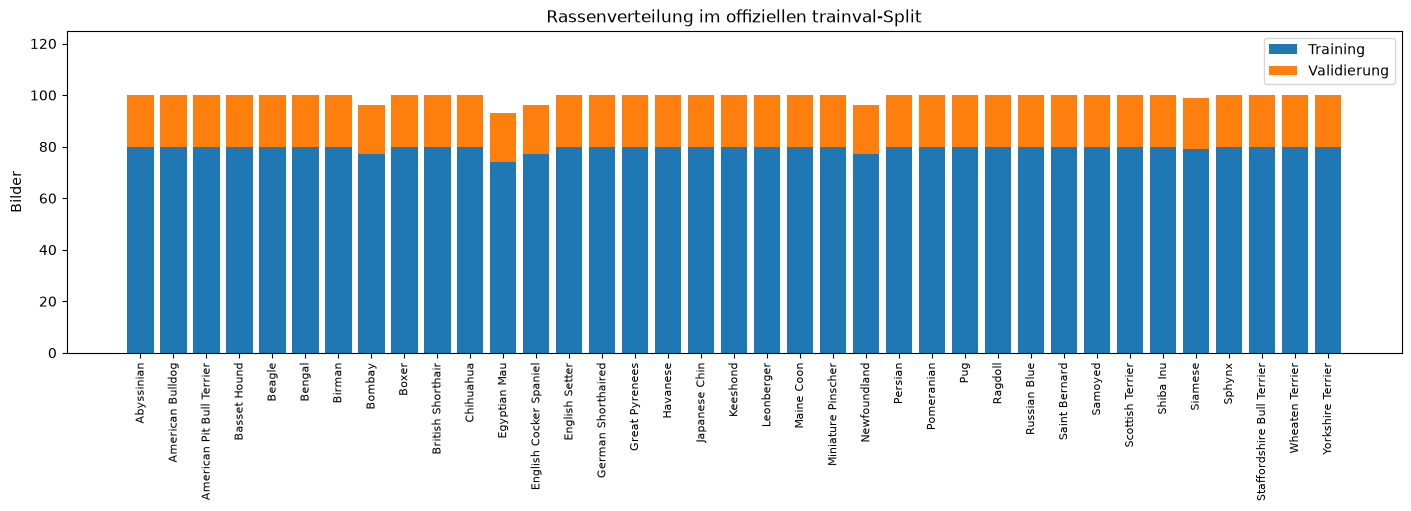

In [ ]:
train_counts = torch.bincount(trainval_labels[train_indices], minlength=N_CLASSES).numpy()
val_counts = torch.bincount(trainval_labels[val_indices], minlength=N_CLASSES).numpy()
positions = np.arange(N_CLASSES)

fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
ax.bar(positions, train_counts, label="Training", color="tab:blue")
ax.bar(positions, val_counts, bottom=train_counts, label="Validierung", color="tab:orange")
ax.set_xticks(positions, class_names, rotation=90, fontsize=8)
ax.set(title="Rassenverteilung im offiziellen trainval-Split", ylabel="Bilder")
ax.set_ylim(0, 1.25 * (train_counts + val_counts).max())
ax.legend(loc="upper right")
plt.show()

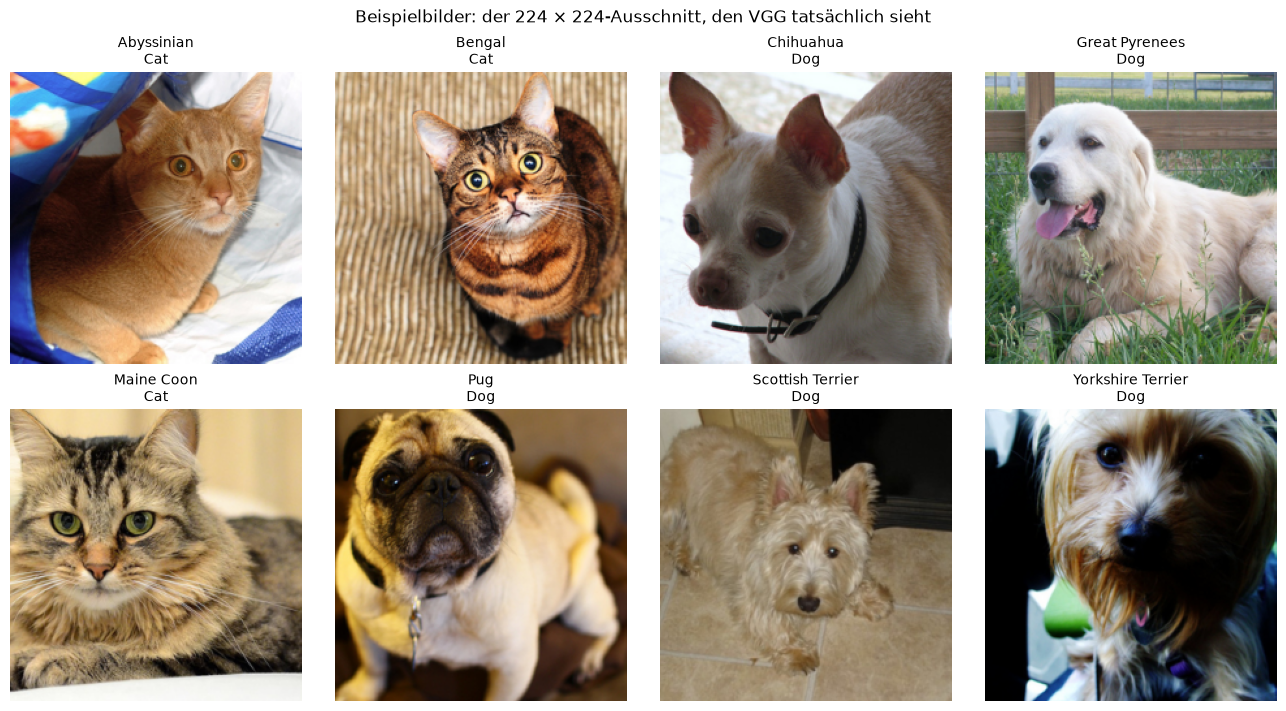

In [ ]:
mean = torch.tensor(PREPROCESSING["mean"]).view(3, 1, 1)
std = torch.tensor(PREPROCESSING["std"]).view(3, 1, 1)

def image_for_plot(image: torch.Tensor) -> np.ndarray:
    """Undo ImageNet normalization for displaying the actual model input."""
    return (image.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


preview_breeds = [0, 5, 10, 15, 20, 25, 30, 36]
fig, axes = plt.subplots(2, 4, figsize=(13, 7), layout="constrained")
for ax, breed_index in zip(axes.flat, preview_breeds, strict=True):
    sample_index = int(torch.where(trainval_labels == breed_index)[0][0])
    image, (label, species) = trainval_dataset[sample_index]
    ax.imshow(image_for_plot(image))
    ax.set_title(f"{class_names[label]}\n{species_names[species]}", fontsize=10)
    ax.axis("off")
fig.suptitle("Beispielbilder: der 224 × 224-Ausschnitt, den VGG tatsächlich sieht")
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 7), layout="constrained")

for ax, breed_index in zip(axes.flat, preview_breeds, strict=True):
    sample_index = int(torch.where(trainval_labels == breed_index)[0][0])
    image, (label, species) = trainval_dataset[sample_index]

    # Normalisierung beibehalten; nur für die RGB-Anzeige auf [0, 1] begrenzen.
    image_display = image.cpu().clamp(0, 1).permute(1, 2, 0).numpy()

    ax.imshow(image_display)
    ax.set_title(
        f"{class_names[label]}\n{species_names[species]}",
        fontsize=10,
    )
    ax.axis("off")

fig.suptitle("Normalisierte Bildwerte als RGB – auf [0, 1] begrenzt")
plt.show()

## 5. Eigenen Klassifikationskopf trainieren

- **Kopf:** `Dropout(p=0.5)` → `Linear(4096, 37)`; insgesamt 151.589 trainierbare Parameter.
- **Loss:** Cross Entropy auf Logits; Softmax gehört nicht vor den Trainingsloss.
- **Optimierer:** AdamW, Lernrate `1e-3`, Weight Decay `1e-4`, Batchgröße 64.
- **Auswahl:** höchstens 30 Epochen; nach fünf Epochen ohne besseren Validierungsverlust stoppen und den besten Stand wiederherstellen.
- **Wiederverwendung:** vorhandene passende Kopfgewichte und ihre Lernkurven laden. Für einen echten Neulauf `RETRAIN_BASELINE` aktivieren.
- Die Trainingsschleife steht einmal in [`train_head`](dan_02_common.py) und wird später für die zusätzlichen Köpfe wiederverwendet.

In [ ]:
CONFIG = {
    "seed": SEED,
    "feature_dim": FEATURE_DIM,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "validation_fraction": 0.2,
    "selection": "minimum validation cross-entropy",
}

CHECKPOINT_PATH = ARTIFACT_DIR / "best_head.pt"
HISTORY_PATH = ARTIFACT_DIR / "training_history.json"
training_start = time.perf_counter()
if CHECKPOINT_PATH.exists() and HISTORY_PATH.exists() and not RETRAIN_BASELINE:
    previous = load_torch(CHECKPOINT_PATH)
    assert previous["config"] == CONFIG
    assert previous["classes"] == class_names
    assert previous["train_image_ids"] == train_ids
    assert previous["validation_image_ids"] == val_ids
    assert previous["weights"] == str(weights)
    assert previous["preprocessing"] == PREPROCESSING
    head = make_head(CONFIG, N_CLASSES, state_dict=previous["head_state_dict"], device=DEVICE)
    best_state = previous["head_state_dict"]
    best_epoch = previous["best_epoch"]
    best_val_loss = previous["best_val_loss"]
    history = json.loads(HISTORY_PATH.read_text())
    print("Passenden gespeicherten Kopf und seine Lernkurven geladen.")
else:
    head = make_head(CONFIG, N_CLASSES, seed=SEED, device=DEVICE)
    fitted = train_head(
        head,
        trainval_features[train_indices], trainval_labels[train_indices],
        trainval_features[val_indices], trainval_labels[val_indices],
        CONFIG, seed=SEED, device=DEVICE,
    )
    best_state, history = fitted["state_dict"], fitted["history"]
    best_epoch, best_val_loss = fitted["best_epoch"], fitted["best_val_loss"]
    print(f"Kopftraining: {time.perf_counter() - training_start:.1f} s.")
print(f"Gewählter Stand: Epoche {best_epoch}, Val-Loss {best_val_loss:.4f}.")


Passenden gespeicherten Kopf und seine Lernkurven geladen.
Gewählter Stand: Epoche 5, Val-Loss 0.2758.


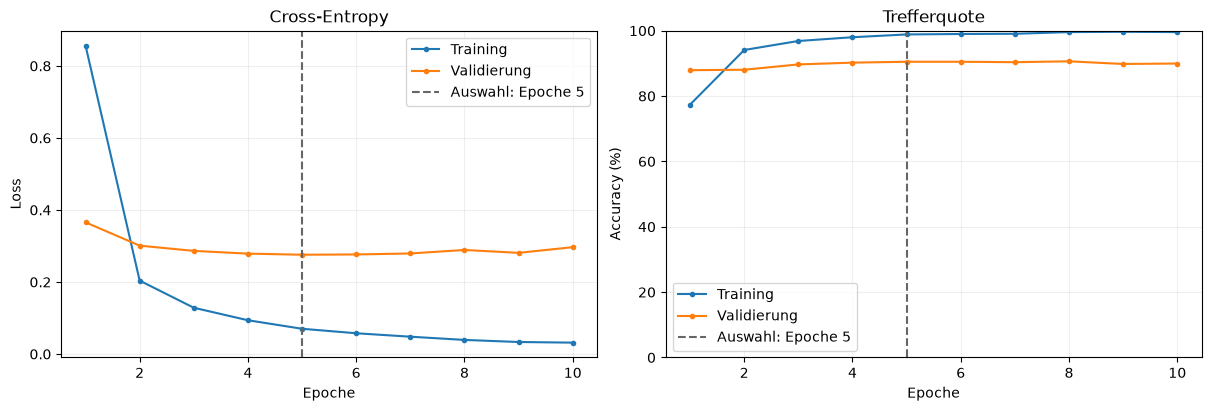

In [ ]:
epochs = [record["epoch"] for record in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for prefix, label in (("train", "Training"), ("val", "Validierung")):
    axes[0].plot(epochs, [record[f"{prefix}_loss"] for record in history], marker=".", label=label)
    axes[1].plot(
        epochs, [100 * record[f"{prefix}_accuracy"] for record in history], marker=".", label=label
    )
for ax in axes:
    ax.axvline(best_epoch, color="0.4", linestyle="--", label=f"Auswahl: Epoche {best_epoch}")
    ax.set_xlabel("Epoche")
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set(title="Cross-Entropy", ylabel="Loss")
axes[1].set(title="Trefferquote", ylabel="Accuracy (%)", ylim=(0, 100))
plt.show()

- Trainings-Accuracy: während der Optimierung mit aktivem Kopf-Dropout gemessen.
- Validierungs-Accuracy: mit deaktiviertem Dropout; sie kann deshalb anfangs höher liegen.
- Der Validierungsverlust bestimmt den gewählten Stand, nicht die höchste Test-Accuracy.

In [ ]:
CHECKPOINT_PATH = ARTIFACT_DIR / "best_head.pt"
checkpoint = {
    "schema_version": 1,
    "head_state_dict": best_state,
    "config": CONFIG,
    "classes": class_names,
    "species": species_names,
    "species_for_breed": species_for_breed,
    "weights": str(weights),
    "preprocessing": PREPROCESSING,
    "versions": VERSIONS,
    "train_image_ids": train_ids,
    "validation_image_ids": val_ids,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
}
save_torch(CHECKPOINT_PATH, checkpoint)
(ARTIFACT_DIR / "training_history.json").write_text(
    json.dumps(history, indent=2), encoding="utf-8"
)
print("Ausgewählten Kopf vor der Testauswertung gespeichert:", CHECKPOINT_PATH)
print(f"Checkpoint-Größe: {CHECKPOINT_PATH.stat().st_size / 1e6:.2f} MB")

Ausgewählten Kopf vor der Testauswertung gespeichert: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/best_head.pt
Checkpoint-Größe: 0.70 MB


## 6. Abschließende Auswertung auf dem offiziellen Testsplit

- **Top-1:** richtig vorhergesagte Rasse.
- **Top-5:** tatsächliche Rasse unter den fünf höchsten Modellwahrscheinlichkeiten.
- **Macro Recall:** jede Rasse gleich gewichten.
- **Katze/Hund:** Wahrscheinlichkeiten aller zugehörigen Rassen summieren; kein zweites Modell trainieren.
- Die Softmax-Werte sind unkalibrierte Modellwahrscheinlichkeiten.

In [ ]:
test_cache = load_or_extract_features(test_dataset, test_ids, "test")
test_features = test_cache["features"]
test_labels = test_cache["labels"]
test_species = test_cache["species"]
assert torch.equal(species_for_breed[test_labels], test_species)


def predict_features(features: torch.Tensor, classifier_head: nn.Module) -> torch.Tensor:
    """Return CPU class probabilities for fixed features in bounded batches."""
    classifier_head.eval()
    batches = []
    with torch.no_grad():
        for batch in features.split(BATCH_SIZE):
            batches.append(classifier_head(batch.to(DEVICE)).softmax(dim=1).cpu())
    return torch.cat(batches)


test_probabilities = predict_features(test_features, head)
assert test_probabilities.shape == (len(test_dataset), N_CLASSES)
assert torch.isfinite(test_probabilities).all()
torch.testing.assert_close(
    test_probabilities.sum(1), torch.ones(len(test_dataset)), rtol=1e-5, atol=1e-6
)
test_predictions = test_probabilities.argmax(1)
species_probabilities = torch.stack(
    [test_probabilities[:, species_for_breed == index].sum(1) for index in range(2)],
    dim=1,
)
species_predictions = species_probabilities.argmax(1)
majority_breed = int(train_counts.argmax())
majority_accuracy = float((test_labels == majority_breed).float().mean())

metrics = {
    "test_images": len(test_dataset),
    "breed_top1": accuracy_score(test_labels.numpy(), test_predictions.numpy()),
    "breed_top5": top_k_accuracy_score(
        test_labels.numpy(), test_probabilities.numpy(), k=5, labels=np.arange(N_CLASSES)
    ),
    "breed_macro_recall": recall_score(
        test_labels.numpy(), test_predictions.numpy(), labels=np.arange(N_CLASSES), average="macro"
    ),
    "species_accuracy": accuracy_score(test_species.numpy(), species_predictions.numpy()),
    "majority_breed_accuracy": majority_accuracy,
}
assert metrics["breed_top1"] > metrics["majority_breed_accuracy"]
display(Markdown(
    f"**Offizieller Testsplit: {metrics['test_images']:,} Bilder**\n\n"
    "| Metrik | Ergebnis |\n| :--- | ---: |\n"
    f"| Rasse: Top-1-Accuracy | {metrics['breed_top1']:.2%} |\n"
    f"| Rasse: Top-5-Accuracy | {metrics['breed_top5']:.2%} |\n"
    f"| Rasse: Macro Recall | {metrics['breed_macro_recall']:.2%} |\n"
    f"| Katze/Hund: Accuracy aus summierten Wahrscheinlichkeiten | {metrics['species_accuracy']:.2%} |\n"
    f"| Vergleich: häufigste Trainingsrasse immer vorhersagen | {majority_accuracy:.2%} |"
))
(ARTIFACT_DIR / "test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

test: passender Cache geladen (test_vgg16_features.pt).


**Offizieller Testsplit: 3,669 Bilder**

| Metrik | Ergebnis |
| :--- | ---: |
| Rasse: Top-1-Accuracy | 90.11% |
| Rasse: Top-5-Accuracy | 99.48% |
| Rasse: Macro Recall | 90.04% |
| Katze/Hund: Accuracy aus summierten Wahrscheinlichkeiten | 99.67% |
| Vergleich: häufigste Trainingsrasse immer vorhersagen | 2.67% |

234

In [ ]:
# Persist ordered predictions and label-only cohorts for all follow-up notebooks.
baseline_logits = head_logits(head, test_features, batch_size=BATCH_SIZE)
torch.testing.assert_close(baseline_logits.softmax(1), test_probabilities, rtol=1e-5, atol=1e-6)
save_torch(ARTIFACT_DIR / "baseline_predictions.pt", {
    "schema_version": 1,
    "logits": baseline_logits,
    "probabilities": test_probabilities,
    "image_ids": test_ids,
    "labels": test_labels,
    "species": test_species,
    "classes": class_names,
    "baseline_fingerprint": state_fingerprint(best_state),
})
selection = write_selection(test_cache, seed=SEED)
print(f"Gemeinsame Auswahl gespeichert: {len(selection['corruption_indices'])} Veränderungsbilder, "
      f"{len(selection['explanation_indices'])} Erklärungsbilder.")

Gemeinsame Auswahl gespeichert: 370 Veränderungsbilder, 37 Erklärungsbilder.


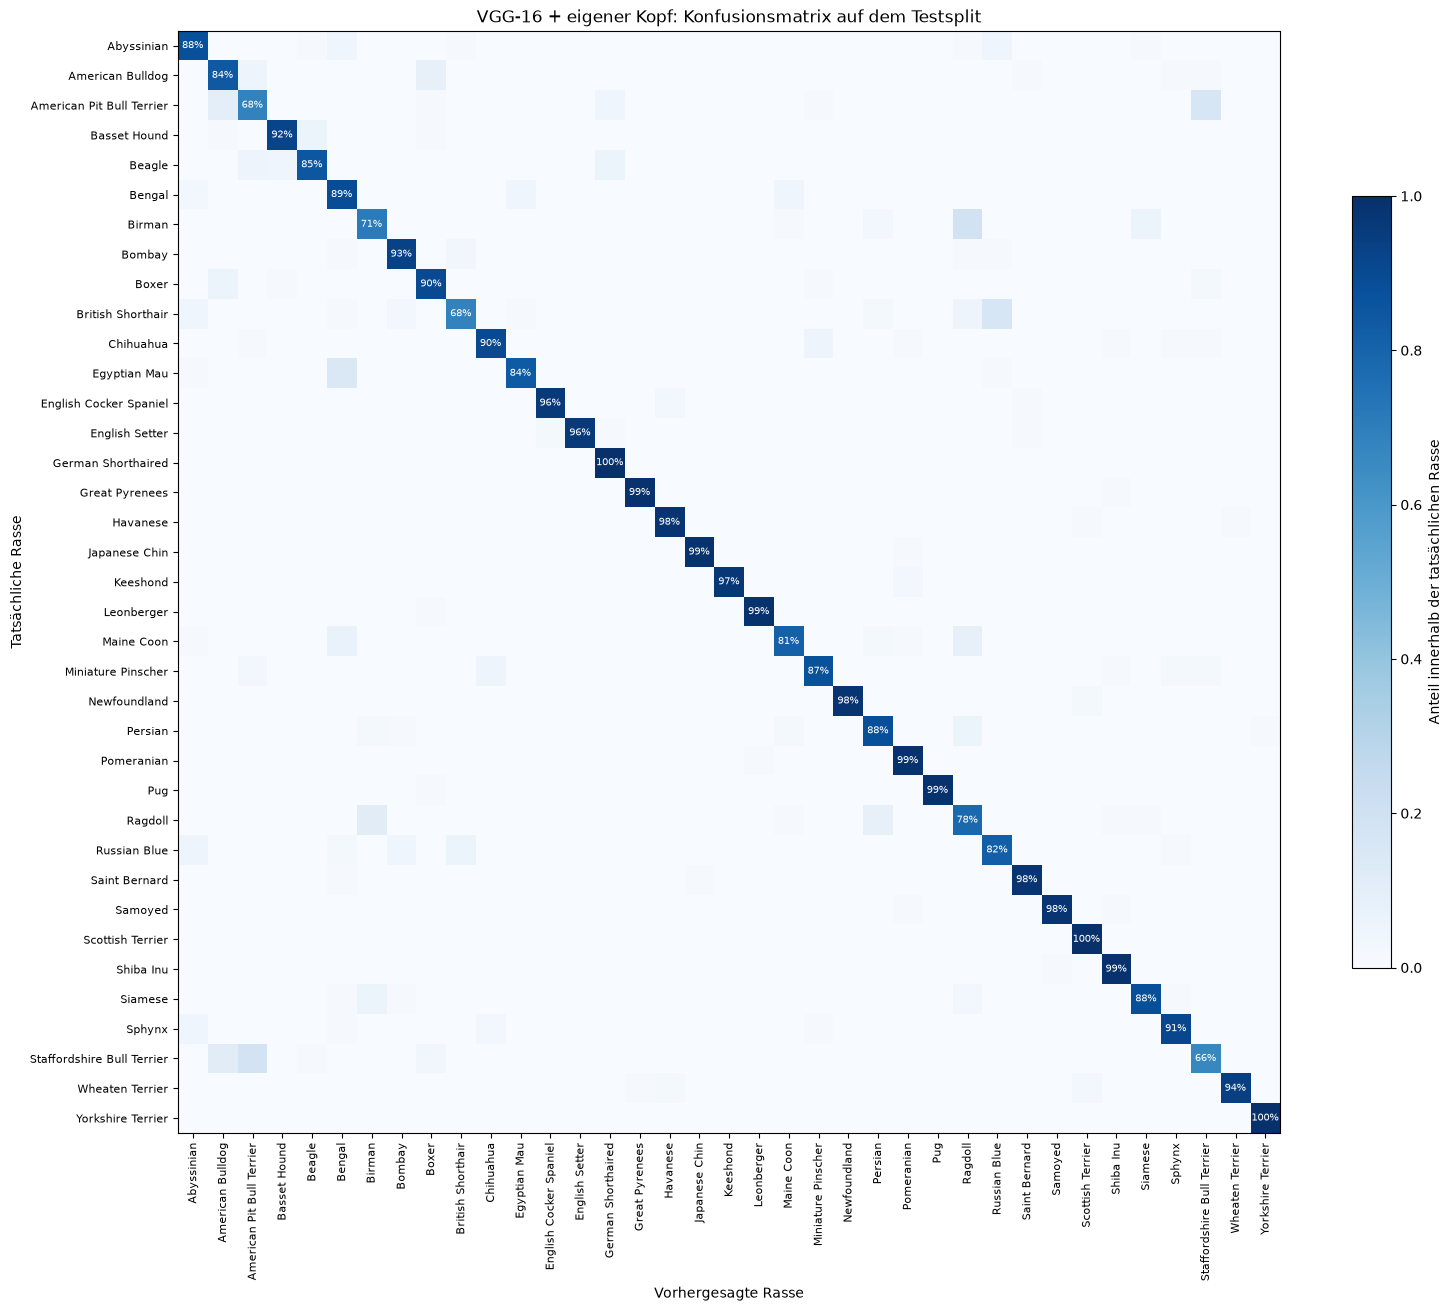

In [ ]:
matrix = confusion_matrix(
    test_labels.numpy(), test_predictions.numpy(), labels=np.arange(N_CLASSES), normalize="true"
)
fig, ax = plt.subplots(figsize=(16, 13), layout="constrained")
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(np.arange(N_CLASSES), class_names, rotation=90, fontsize=8)
ax.set_yticks(np.arange(N_CLASSES), class_names, fontsize=8)
ax.set(
    title="VGG-16 + eigener Kopf: Konfusionsmatrix auf dem Testsplit",
    xlabel="Vorhergesagte Rasse",
    ylabel="Tatsächliche Rasse",
)
for index in range(N_CLASSES):
    ax.text(
        index, index, f"{matrix[index, index]:.0%}", ha="center", va="center",
        fontsize=7, color="white" if matrix[index, index] > 0.5 else "black",
    )
fig.colorbar(image, ax=ax, shrink=0.7, label="Anteil innerhalb der tatsächlichen Rasse")
plt.show()

- Die Konfusionsmatrix ist **zeilenweise normiert**: jede Zeile beschreibt eine tatsächliche Rasse.
- Diagonale = richtige Vorhersagen; dunklere Felder daneben = Verwechslungen.
- Die Galerien zeigen bis zu sechs verschiedene Rassen: gleichmäßig über die verfügbaren Klassen verteilt, jeweils das erste passende Bild.
- Richtige und falsche Vorhersagen werden absichtlich getrennt gezeigt. Das ist keine repräsentative Stichprobe.
- Unter jedem Bild stehen die drei höchsten Modellwahrscheinlichkeiten.

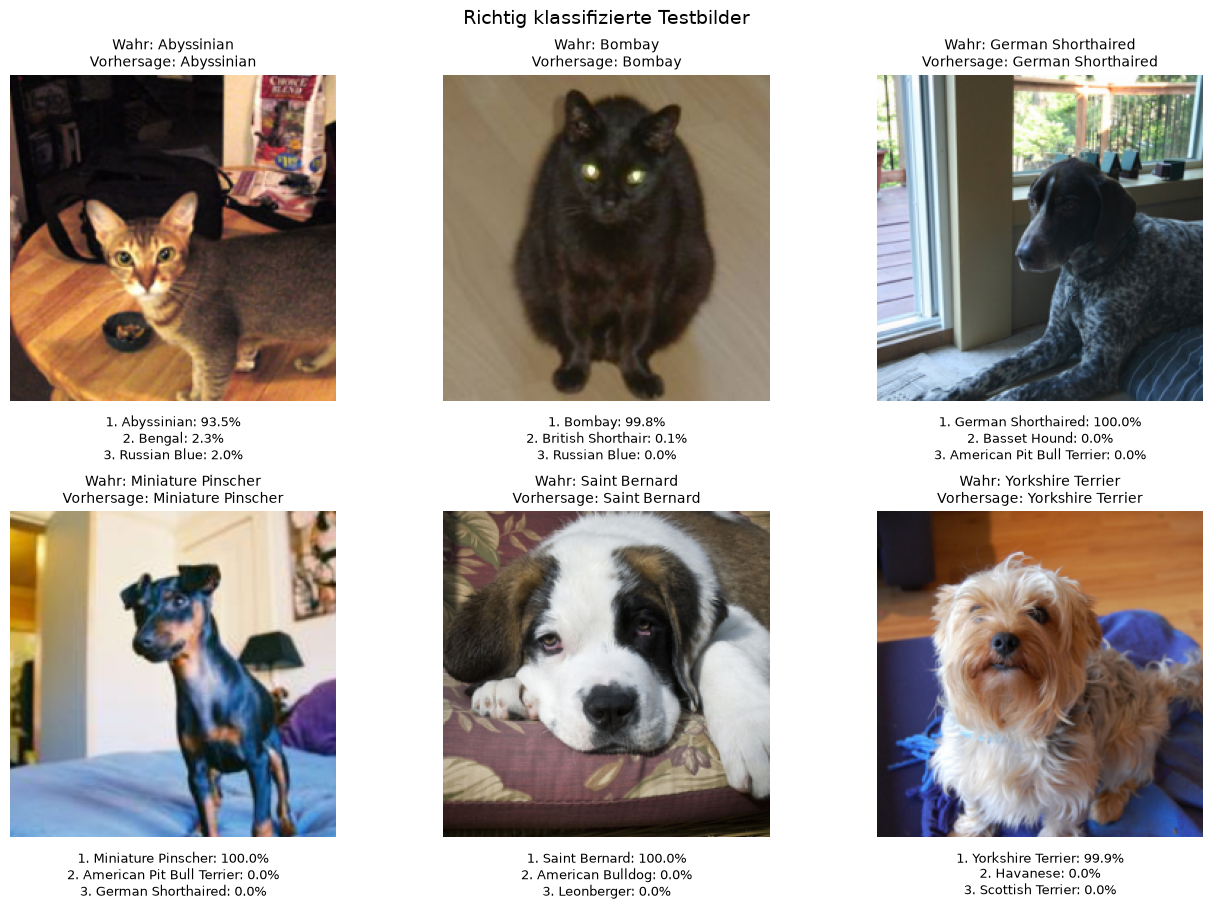

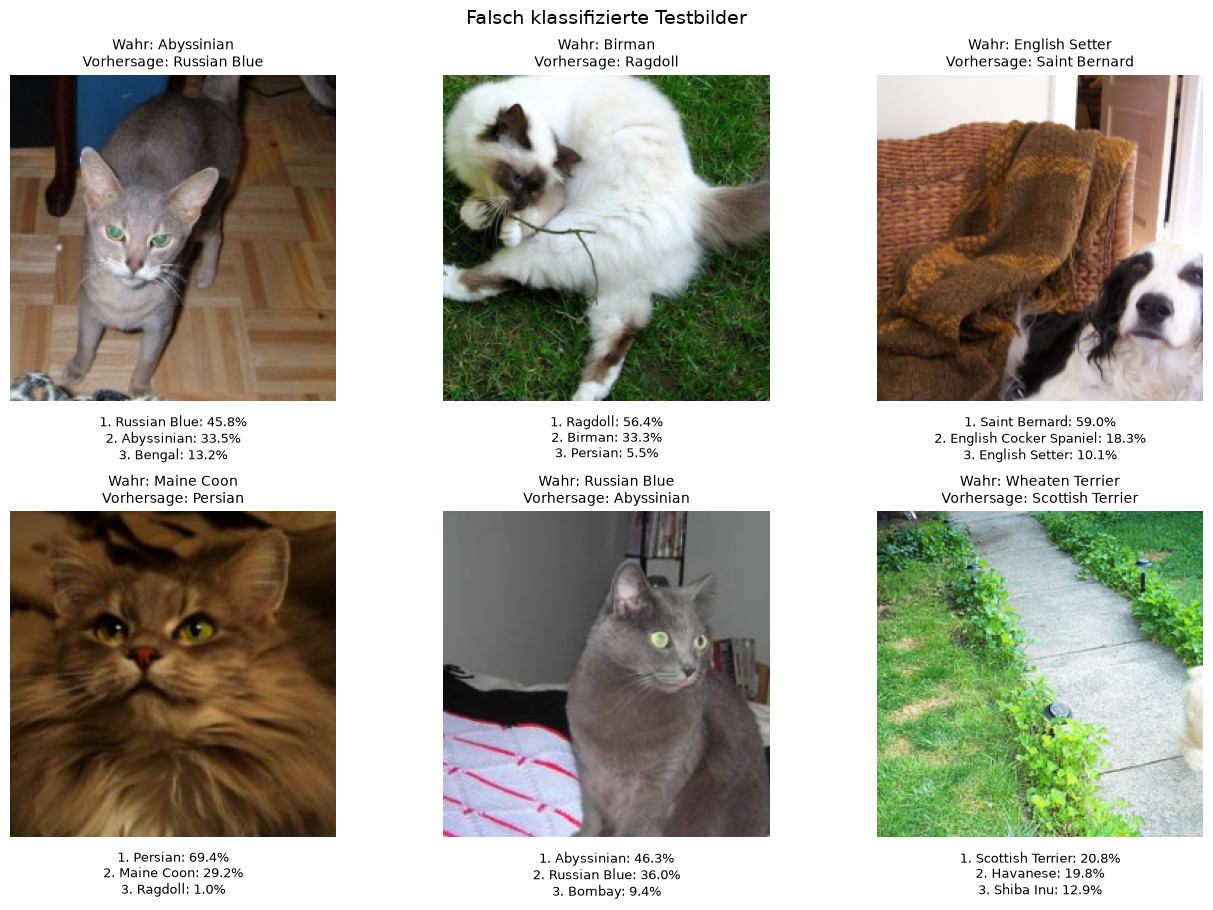

In [ ]:
def show_prediction_gallery(indices: np.ndarray, title: str) -> None:
    """Show actual model inputs with true labels and top-three predictions."""
    if len(indices) == 0:
        print(f"{title}: keine Beispiele.")
        return
    candidate_labels = test_labels[indices].numpy()
    breeds = np.unique(candidate_labels)
    breeds = breeds[np.linspace(0, len(breeds) - 1, min(6, len(breeds)), dtype=int)]
    selected = [indices[np.flatnonzero(candidate_labels == breed)[0]] for breed in breeds]
    fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, selected):
        image, (label, _) = test_dataset[int(index)]
        values, breed_indices = test_probabilities[int(index)].topk(3)
        ax.imshow(image_for_plot(image))
        ax.set_title(
            f"Wahr: {class_names[label]}\nVorhersage: {class_names[test_predictions[index]]}",
            fontsize=10,
        )
        description = "\n".join(
            f"{rank}. {class_names[breed]}: {probability:.1%}"
            for rank, (breed, probability) in enumerate(
                zip(breed_indices.tolist(), values.tolist(), strict=True), start=1
            )
        )
        ax.text(
            0.5, -0.04, description, transform=ax.transAxes, ha="center", va="top", fontsize=9
        )
    fig.suptitle(title, fontsize=14)
    plt.show()


correct_indices = torch.where(test_predictions == test_labels)[0].numpy()
error_indices = torch.where(test_predictions != test_labels)[0].numpy()
show_prediction_gallery(correct_indices, "Richtig klassifizierte Testbilder")
show_prediction_gallery(error_indices, "Falsch klassifizierte Testbilder")

## 7. Checkpoint laden und vollständige Bildklassifikation prüfen

- Gespeichert: kleiner Kopf, Klassenbelegung, Vorverarbeitung, Split-IDs und Trainingskonfiguration.
- Vortrainierte VGG-Gewichte: separat im lokalen torch-Hub-Cache.
- Den Kopf aus seinem Checkpoint rekonstruieren und hinter den eingefrorenen Backbone setzen.
- Zwei Vergleiche: ursprünglicher gegen geladener Kopf auf Merkmalen und vollständiger Weg Bild → VGG → Kopf.
- `classify_image` demonstriert anschließend die Vorhersage für ein gewöhnliches PIL-Bild.

In [ ]:
loaded_checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
assert loaded_checkpoint["classes"] == class_names
assert loaded_checkpoint["weights"] == str(weights)
assert loaded_checkpoint["preprocessing"] == PREPROCESSING
assert loaded_checkpoint["train_image_ids"] == train_ids
assert loaded_checkpoint["validation_image_ids"] == val_ids

reloaded_head = nn.Sequential(
    nn.Dropout(loaded_checkpoint["config"]["dropout"]),
    nn.Linear(loaded_checkpoint["config"]["feature_dim"], len(loaded_checkpoint["classes"])),
).to(DEVICE)
reloaded_head.load_state_dict(loaded_checkpoint["head_state_dict"])
reloaded_head.eval()
full_classifier = nn.Sequential(backbone, reloaded_head).eval()

sample_images = torch.stack([test_dataset[index][0] for index in range(EXTRACTION_BATCH_SIZE)])
with torch.no_grad():
    original_logits = head(test_features[:EXTRACTION_BATCH_SIZE].to(DEVICE)).cpu()
    reloaded_logits = reloaded_head(test_features[:EXTRACTION_BATCH_SIZE].to(DEVICE)).cpu()
    image_logits = full_classifier(sample_images.to(DEVICE)).cpu()
torch.testing.assert_close(reloaded_logits, original_logits, rtol=1e-5, atol=1e-6)
torch.testing.assert_close(image_logits, original_logits, rtol=1e-4, atol=1e-4)
assert not any(parameter.requires_grad for parameter in backbone.parameters())
print("Wiederladen und Bild → VGG → Kopf stimmen mit den gespeicherten Merkmalen überein.")

Wiederladen und Bild → VGG → Kopf stimmen mit den gespeicherten Merkmalen überein.


In [ ]:
def classify_image(image: PILImage.Image) -> dict:
    """Classify a PIL image with the reloaded model.

    Args:
        image: Input image; it is converted to RGB and preprocessed like the dataset.

    Returns:
        Predicted breed and species plus the three highest breed probabilities.
    """
    full_classifier.eval()
    with torch.no_grad():
        probabilities = full_classifier(preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE))
        probabilities = probabilities.softmax(1).cpu()[0]
    values, indices = probabilities.topk(3)
    species_scores = torch.stack(
        [probabilities[species_for_breed == index].sum() for index in range(2)]
    )
    return {
        "breed": class_names[int(probabilities.argmax())],
        "species": species_names[int(species_scores.argmax())],
        "top3": [
            {"breed": class_names[breed], "probability": probability}
            for breed, probability in zip(indices.tolist(), values.tolist(), strict=True)
        ],
    }


# Use an ordinary PIL image so this example includes RGB conversion and preprocessing.
raw_test_dataset = OxfordIIITPet(
    DATA_ROOT, split="test", target_types=("category", "binary-category"), download=False
)
example_image, (example_label, _) = raw_test_dataset[0]
example_prediction = classify_image(example_image)
print("Tatsächliche Rasse:", class_names[example_label])
print(json.dumps(example_prediction, indent=2))

Tatsächliche Rasse: Abyssinian
{
  "breed": "Abyssinian",
  "species": "Cat",
  "top3": [
    {
      "breed": "Abyssinian",
      "probability": 0.9345148205757141
    },
    {
      "breed": "Bengal",
      "probability": 0.023199351504445076
    },
    {
      "breed": "Russian Blue",
      "probability": 0.020266057923436165
    }
  ]
}


## 8. Übergabe an die nächsten Notebooks

- **Gespeichert:** Kopf, trainval-/Testmerkmale, geordnete Testvorhersagen, Lernkurven, Testmetriken und gemeinsame Bildauswahl.
- **02-1 · probly:** MC Dropout, Kopfensemble, Fehlererkennung, Veränderungen und Datenknappheit.
- **02-2 · shapiq:** Rassenwahrscheinlichkeiten, Bildregionen, Wechselwirkungen und Robustheit der Erklärungen.
- **02-3 · Kombination:** dieselben Bildregionen zur Erklärung der probly-Unsicherheit verwenden.
- probly und shapiq benötigen dieses Training nicht erneut. Die nachfolgenden Notebooks laden die Artefakte mit [`dan_02_common.py`](dan_02_common.py).

### Grenzen der Baseline

- **Transferwissen:** ImageNet enthält bereits Katzen- und Hundeklassen. Hier messen wir Transfer Learning, kein Lernen ohne Vorwissen.
- **Feste Merkmale:** der neue Kopf kann Fehler des eingefrorenen VGG-Backbones nicht vollständig beheben.
- **Center Crop:** das Modell sieht nur den gezeigten Ausschnitt; abgeschnittene Tiere können schwierige oder irreführende Eingaben ergeben.
- **Testdaten:** dienen der Auswertung; weitere Modellwahl erfolgt weiterhin über die Validierung.

### Quellen

- [Oxford-IIIT Pet: Datensatz und Originalarbeit](https://www.robots.ox.ac.uk/~vgg/data/pets/)
- [torchvision OxfordIIITPet](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html)
- [torchvision VGG16: Gewichte und Vorverarbeitung](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html)
- [PyTorch: Transfer Learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)